# Does phrasing change spurious forgetting?

This notebook extends the repository's Figure 1 synthetic-biography experiment. It crosses **shared templates** and **structural paraphrases** with **concentrated** answers (the repository's `disjoint`, Y only) and **mixed** answers (its `all_values`, X ∪ Y). Paper group B is called `ballast` in the code. The new people stay the same across all four conditions. Within an answer regime, both wording arms see the same biographies' structured facts in the same sampled order.

Use a Jupyter kernel with the project's JAX and analysis dependencies and `ipykernel`. Open this notebook from the repository root or `notebooks/`. Run the repository's preprocessing with `python -m src.data.preprocess_biography`. For the Figure 1 mode, supply the matching checkpoint and value partition produced by `python -m src.experiments.mlpfree_pretrain` as described in the README. On Colab, follow the [Colab GPU setup](../README.md#colab-gpu-setup) and restart the session after installing the compatible JAX stack. Figure 1 mode uses every evaluation person and the repository's 1,200-step injection schedule. CPU smoke mode exercises the workflow on a small, briefly pretrained model. Its curves are plumbing checks.

Light paraphrases would add a third level to the same factorial design. Biographies about different attributes belong in a separate follow-up because their target values also change.

In [21]:
%pwd
# %cd spurious-forgetting-mechanics

'/content/spurious-forgetting-mechanics'

### Prepare or restore the paper checkpoint

Run the Colab setup from the README first. Use the cells below to create a new run from the checkout root. The default step-16,000 checkpoint is written only when pretraining reaches that step. A value partition can already exist before the first checkpoint is saved.

To reuse a previous run, skip both shell commands and restore its `preprocessed.npz`, `value_partition.npz`, and checkpoint. In Colab, save these artifacts to persistent storage before disconnecting. If the checkpoint is outside the checkout, update `CHECKPOINT_DIR` in the configuration cell. The notebook checks the experiment key before loading it.

In [ ]:
!python -m src.data.preprocess_biography
if get_ipython().user_ns["_exit_code"] != 0:
    raise RuntimeError("Biography preprocessing failed. Check the output above before continuing.")
from pathlib import Path
if not Path("data/biography/preprocessed.npz").is_file():
    raise FileNotFoundError("Expected data/biography/preprocessed.npz in the checkout after biography preprocessing.")

In [ ]:
!python -m src.experiments.mlpfree_pretrain
if get_ipython().user_ns["_exit_code"] != 0:
    raise RuntimeError("MLP-free pretraining failed. Check the output above before continuing.")
from pathlib import Path
if not Path("data/biography/value_partition.npz").is_file():
    raise FileNotFoundError("Expected data/biography/value_partition.npz in the checkout after mlp-free pretraining.")
if not any(path.is_file() for path in Path("checkpoints").glob("mlpfree-pretrain-*-step16000.msgpack")):
    raise FileNotFoundError(
        "Pretraining returned without a step-16000 checkpoint in checkpoints/. "
        "Check the training output for an early stop."
    )

In [22]:
from copy import copy
from dataclasses import replace
from importlib.metadata import PackageNotFoundError, version
from pathlib import Path
from tempfile import mkdtemp
import os
import sys

from packaging.version import Version

MODE = "paper"                 # "smoke" for a CPU workflow check
if MODE not in {"paper", "smoke"}:
    raise ValueError('MODE must be "paper" or "smoke".')
if MODE == "smoke":
    os.environ["JAX_PLATFORMS"] = "cpu"

colab_setup = "Colab CPU smoke run" if MODE == "smoke" else "Colab GPU setup"
jax_setup = (
    "Use the project's JAX/JAXLIB range (>=0.4.34,<0.5). In Colab, follow "
    f"README.md → {colab_setup}, then restart the session."
)
for package in ("jax", "jaxlib"):
    try:
        installed = Version(version(package)).base_version
    except PackageNotFoundError as exc:
        raise RuntimeError(f"{package} is missing. {jax_setup}") from exc
    if not Version("0.4.34") <= Version(installed) < Version("0.5"):
        raise RuntimeError(f"Found {package} {installed}. {jax_setup}")

# Colab can retain its CUDA 13 plugin after installing the JAX 0.4 CUDA 12 stack.
if MODE == "paper":
    for package in ("jax-cuda13-plugin", "jax-cuda13-pjrt"):
        try:
            version(package)
        except PackageNotFoundError:
            continue
        raise RuntimeError(
            f"Found {package} with JAX 0.4. In Colab, run "
            "%pip uninstall -y jax-cuda13-plugin jax-cuda13-pjrt, then restart the session."
        )

# A running Colab kernel can retain old modules after %pip replaces packages on disk.
for package in ("jax", "jaxlib", "flax", "optax"):
    loaded = getattr(sys.modules.get(package), "__version__", None)
    if loaded is not None and loaded != version(package):
        raise RuntimeError(f"{package} {loaded} is still loaded. Restart the session after installation.")

import jax

if MODE == "smoke":
    jax.config.update("jax_platforms", "cpu")

import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

root = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "src/experiments/mlpfree_pretrain.py").is_file()), None)
if root is None:
    raise RuntimeError("Open the notebook from the repository root or notebooks/.")

os.chdir(root)
sys.path.insert(0, str(root))

from src.data.biography import BiographyDataset, NUM_ATTRIBUTES
from src.data.biography_corpus import ATTRIBUTE_NAMES, FIRST_NAMES, LAST_NAMES, MIDDLE_NAMES, TEMPLATES
from src.experiments.ckpt import file_hash, load_state
from src.experiments.knowledge_injection import (
    INJECT_LR_RATIO, KIConfig, build, first_token_positions, get_partition, init_state,
    make_optimizer, reset_stream,
)
from src.experiments.mlpfree_common import (
    MODEL_DIM, NUM_HEADS, NUM_LAYERS, create_mlpfree_model, mlpfree_pretrain_key,
)
from src.experiments.mlpfree_pretrain import PEAK_LR, TOTAL_STEPS
from src.train import train_step

PRETRAIN_STEP = 16000
INJECTION_SEED = 0             # repeat the complete grid with additional seeds
EXTERNAL_EMBEDDINGS = False     # enable after installing sentence-transformers in this kernel
ENCODER_ID = "sentence-transformers/all-MiniLM-L6-v2"
CORPUS = Path("data/biography/preprocessed.npz")  # the path string is part of the checkpoint key
PARTITION = root / "data/biography/value_partition.npz"
CHECKPOINT_DIR = root / "checkpoints"  # point this at the saved checkpoint directory if restoring from Drive
PROBE_PEOPLE = 96
print(f"JAX {jax.__version__} on {jax.default_backend()}")
if not CORPUS.is_file():
    raise FileNotFoundError(f"{CORPUS} is missing. Run python -m src.data.preprocess_biography.")
if MODE == "paper" and not PARTITION.is_file():
    raise FileNotFoundError(
        f"Missing value partition: {PARTITION}. Restore it with its matching checkpoint, "
        "or run python -m src.experiments.mlpfree_pretrain to create both."
    )
output = Path(mkdtemp(prefix="biography-wording-"))
print("Results directory", output)

JAX 0.4.38 on gpu
Results directory /tmp/biography-wording-q4avnf5_


In [23]:
# %pip uninstall -y jax-cuda13-plugin jax-cuda13-pjrt

print(jax.__version__, jax.devices())
assert any(device.platform == "gpu" for device in jax.devices())

0.4.38 [CudaDevice(id=0)]


## 1. Recreate the two answer regimes and load one checkpoint

The dataset builder fixes the population and value split. Each person has one value per attribute. Both regimes use the same seed and population sizes. Changing the injection pool leaves old prompts and old facts unchanged. All four arms start from identical parameters, fresh AdamW state, and the same constant learning rate.

In [24]:
paper = MODE == "paper"
base = KIConfig()
cfg = replace(
    base, model=replace(base.model, model_dim=MODEL_DIM if paper else 32, num_heads=NUM_HEADS if paper else 4,
                        num_layers=NUM_LAYERS if paper else 1, mlp_coefficient=0, dropout_rate=0.0),
    data=replace(base.data, biography_data_path=str(CORPUS), support_size=1),
    pretrain=replace(base.pretrain, total_steps=TOTAL_STEPS if paper else 20,
                     batch_size=256 if paper else 8, opt=replace(base.pretrain.opt, peak_lr=PEAK_LR)),
    inject=replace(base.inject, total_steps=1200 if paper else 12, batch_size=256 if paper else 8,
                   seed=INJECTION_SEED, opt=replace(base.inject.opt, peak_lr=PEAK_LR / INJECT_LR_RATIO)),
    num_a=2000 if paper else 16, num_ballast=2000 if paper else 16,
    num_b=500 if paper else 12, num_c=500 if paper else 0,
    partition_path=str(PARTITION if paper else output / "value_partition.npz"),
)
STEPS = (0, 10, 25, 50, 100, 200, 400, 600, 800, 1000, 1200) if paper else (0, 2, 4, 8, 12)
EVAL_BATCH = 16 if paper else 8
REGIMES = {"concentrated": "disjoint", "mixed": "all_values"}
WORDINGS = ("shared", "structural")
built = {
    regime: build(replace(cfg, inject=replace(cfg.inject, condition=condition)), 0)
    for regime, condition in REGIMES.items()
}
pop, _, data_cfg, pretrain, old_a, old_b, _, _ = built["concentrated"]
halves = get_partition(cfg, pop)
model = create_mlpfree_model(cfg.model, data_cfg)
def locate_paper_checkpoint(directory, key, step):
    directory = Path(directory)
    expected = directory / f"mlpfree-pretrain-{key}-step{step:05d}.msgpack"
    if expected.is_file():
        return expected

    candidates = sorted(p.name for p in directory.glob("mlpfree-pretrain-*-step*.msgpack") if p.is_file())
    same_run = [name for name in candidates if name.startswith(f"mlpfree-pretrain-{key}-")]
    if same_run:
        detail = f"Steps saved for this run: {', '.join(same_run)}."
    elif candidates:
        detail = (
            f"Checkpoints in this directory have different experiment keys: {', '.join(candidates)}. "
            "Use the corpus, value partition, and configuration from the run that wrote the checkpoint."
        )
    else:
        detail = "No MLP-free pretraining checkpoints were found in this directory."
    raise FileNotFoundError(
        f"Matching checkpoint missing: {expected}\n{detail}\n"
        "If the checkpoint is saved elsewhere, update CHECKPOINT_DIR and restore the matching corpus "
        f"and partition. Otherwise, run the pretraining cell and check that it reports step {step} "
        "among the saved checkpoints."
    )


checkpoint = locate_paper_checkpoint(CHECKPOINT_DIR, mlpfree_pretrain_key(cfg, data_cfg), PRETRAIN_STEP) if paper else None
pre_template = init_state(model, cfg, data_cfg, make_optimizer(cfg.pretrain.opt, cfg.pretrain.total_steps),
                          cfg.seed + 10)
if paper:
    params0, _, checkpoint_step = load_state(str(checkpoint), pre_template)
    if checkpoint_step != PRETRAIN_STEP:
        raise ValueError(f"{checkpoint} contains step {checkpoint_step}; expected {PRETRAIN_STEP}.")
else:
    reset_stream(pretrain, cfg.seed + 1)
    state = pre_template
    for _ in range(cfg.pretrain.total_steps):
        state, _ = train_step(state, pretrain.get_batch(state.rng, cfg.pretrain.batch_size),
                              BiographyDataset.loss_fn)
    params0 = state.params

initial = init_state(model, cfg, data_cfg, make_optimizer(cfg.inject.opt, cfg.inject.total_steps),
                     cfg.seed + 20).replace(params=params0)
for left, right in zip((old_a, old_b), built["mixed"][4:6]):
    for field in ("eval_inputs", "eval_targets", "eval_mask"):
        np.testing.assert_array_equal(getattr(left, field), getattr(right, field))
np.testing.assert_array_equal(built["concentrated"][0].person_names, built["mixed"][0].person_names)

Loaded value partition from /content/spurious-forgetting-mechanics/data/biography/value_partition.npz
Vocab 1881, seq_len 195, prompt_len 15
People: A=2000, ballast=2000, B=500, C=500 (never trained); condition=disjoint (B draws from Y, C from X)
Loaded value partition from /content/spurious-forgetting-mechanics/data/biography/value_partition.npz
Vocab 1881, seq_len 195, prompt_len 15
People: A=2000, ballast=2000, B=500, C=500 (never trained); condition=all_values (B draws from all, C from X)
Loaded value partition from /content/spurious-forgetting-mechanics/data/biography/value_partition.npz


FileNotFoundError: Matching checkpoint missing: /content/spurious-forgetting-mechanics/checkpoints/mlpfree-pretrain-c22ea30bb964-step16000.msgpack

## 2. Render identical facts two ways

Shared training uses the original per-person training templates. Structural training uses short dossier entries, such as “The birth year of Ada … . 1912.” The name–attribute heading and the answer fragment use existing checkpoint tokens. Each structural heading comes from a repository template's noun phrase. The variants keep name and answer token IDs, attribute order, and person exposure fixed. The number of distinct phrasings, syntax, and token positions can change, so the experiment estimates the effect of this **rendering policy**. It cannot isolate syntax from those other wording changes.

The old and new recall curves all use the repository's fixed held-out original templates. Within each pool, both wording arms are scored on exactly the same rows. Across pools, the new evaluation prompts use the same template draws and people, but the answers and earlier sentences in a biography can differ.

In [ ]:
# The repository splices tokens at [X] and [Y] when rendering a biography.
# Reuse the original tokenized noun phrases and sentence-ending period.
def dossier_bank(population):
    token_tables, texts = [], []
    for k, attr in enumerate(ATTRIBUTE_NAMES):
        ids = population.attr_template_ids["en"][k]
        lengths = population.attr_template_lengths["en"][k]
        period = ids[0, lengths[0] - 1]
        alternatives = []
        for template_id, template in enumerate(TEMPLATES[attr]):
            heading, tail = template.split("[X]")
            if not heading.startswith("The ") or not heading.rstrip().endswith((" of", " for", " by")):
                continue
            if "[Y]" in heading or "[Y]" not in tail:
                continue
            source = ids[template_id, :lengths[template_id]]
            name_slot = np.flatnonzero(source == population.x_id).item()
            tokens = np.r_[source[:name_slot + 1], period, population.y_id, period]
            alternatives.append((tokens, heading + "[X]. [Y]."))
        if not alternatives:
            raise ValueError(f"No checkpoint-compatible dossier heading for {attr}")
        count = len(TEMPLATES[attr])
        chosen = [alternatives[i % len(alternatives)] for i in range(count)]
        lens = np.array([len(tokens) for tokens, _ in chosen])
        padded = np.full((count, lens.max()), population.pad_id, dtype=np.int32)
        for i, (tokens, _) in enumerate(chosen):
            padded[i, :len(tokens)] = tokens
        token_tables.append((padded, lens))
        texts.append([text for _, text in chosen])
    return token_tables, texts


def training_view(dataset, wording):
    # The frozen eval arrays already exist on this shallow copy. Only its training
    # template table changes. Reset the native sampler before serving any batches.
    view = copy(dataset)
    view.exposure_counts = np.zeros_like(dataset.exposure_counts)
    if wording == "structural":
        view.pop = copy(dataset.pop)
        tables, _ = dossier_bank(dataset.pop)
        view.pop.attr_template_ids = {"en": [ids for ids, _ in tables]}
        view.pop.attr_template_lengths = {"en": [lens for _, lens in tables]}
        longest = [int(lens.max()) - 2 + dataset.pop.max_name_len
                   + int(dataset.pop.attr_value_lengths[k].max())
                   for k, (_, lens) in enumerate(tables)]
        assert dataset.pop.prompt_len + sum(longest) <= dataset.pop.seq_len
    reset_stream(view, cfg.seed + 5 + INJECTION_SEED)
    return view


def fact_values(dataset, people):
    probabilities = [p[people] for p in dataset.pop.value_probs]
    assert all(np.all((p > 0).sum(axis=1) == 1) for p in probabilities)
    return np.stack([p.argmax(axis=1) for p in probabilities], axis=1)


def triples(dataset, people):
    return {(int(person), k, int(value))
            for person, values in zip(people, fact_values(dataset, people))
            for k, value in enumerate(values)}


def slots(targets, mask):
    positions, answers = zip(*(first_token_positions(mask, targets, k) for k in range(NUM_ATTRIBUTES)))
    return np.stack(positions, axis=1), np.stack(answers, axis=1)


pool_rows, render_rows = [], []
for regime, experiment in built.items():
    new = experiment[6]
    shared, structural = [training_view(new, wording) for wording in WORDINGS]
    for field in ("eval_inputs", "eval_targets", "eval_mask"):
        np.testing.assert_array_equal(getattr(shared, field), getattr(structural, field))
    facts = triples(shared, new.person_ids)
    assert facts == triples(structural, new.person_ids)
    assert not set(new.person_ids) & (set(old_a.person_ids) | set(old_b.person_ids))
    assert not facts & (triples(old_a, old_a.person_ids) | triples(old_b, old_b.person_ids))

    # Inspect the same seeded training draw used by each arm.
    paired = [view._generate(64, False, np.random.default_rng(cfg.seed + 5 + INJECTION_SEED))
              for view in (shared, structural)]
    np.testing.assert_array_equal(paired[0][2], paired[1][2])
    sampled_values = fact_values(new, paired[0][2])
    expected = np.stack([pop.attr_first_token_ids[k][sampled_values[:, k]]
                         for k in range(NUM_ATTRIBUTES)], axis=1)
    order_reference = None
    for wording, (sequences, masks, _, _) in zip(WORDINGS, paired):
        pos, answers = slots(sequences[:, 1:], masks[:, 1:])
        np.testing.assert_array_equal(answers, expected)
        if order_reference is None:
            order_reference = pos.argsort(axis=1)
        np.testing.assert_array_equal(pos.argsort(axis=1), order_reference)
        render_rows.append(dict(pool=regime, wording=wording,
                                mean_answer_position=pos.mean(),
                                mean_nonpad_tokens=np.count_nonzero((masks != 0) & (masks != 8), axis=1).mean()))
    for k, attr in enumerate(ATTRIBUTE_NAMES):
        values = fact_values(new, new.person_ids)[:, k]
        x, y = halves[k]
        expected_pool = y if regime == "concentrated" else np.r_[x, y]
        assert np.isin(values, expected_pool).all()
        row = dict(pool=regime, attribute=attr, fraction_from_x=np.isin(values, x).mean(),
                   old_new_exact_triple_overlap=0, paired_wording_exact_triple_match=1.0)
        for label, old in (("A", old_a), ("B", old_b)):
            old_values = fact_values(old, old.person_ids)[:, k]
            row[f"new_answer_occurrence_in_old_{label}"] = np.isin(values, old_values).mean()
            row[f"unique_answer_jaccard_with_{label}"] = len(set(values) & set(old_values)) / len(
                set(values) | set(old_values))
        pool_rows.append(row)
pool_overlap = pd.DataFrame(pool_rows)
render_checks = pd.DataFrame(render_rows)
display(render_checks, pool_overlap)

,pool,wording,mean_answer_position,mean_nonpad_tokens
0,concentrated,shared,69.489583,109.093750
1,concentrated,structural,67.203125,104.093750
2,mixed,shared,69.611979,109.234375
3,mixed,structural,67.325521,104.234375


,pool,attribute,fraction_from_x,old_new_exact_triple_overlap,paired_wording_exact_triple_match,new_answer_occurrence_in_old_A,unique_answer_jaccard_with_A,new_answer_occurrence_in_old_B,unique_answer_jaccard_with_B
0,concentrated,birthdate,0.000000,0,1.0,0.000000,0.000000,0.250000,0.125000
1,concentrated,birthplace,0.000000,0,1.0,0.000000,0.000000,0.416667,0.250000
2,concentrated,university,0.000000,0,1.0,0.000000,0.000000,0.250000,0.136364
3,concentrated,major,0.000000,0,1.0,0.000000,0.000000,0.333333,0.173913
4,concentrated,company,0.000000,0,1.0,0.000000,0.000000,0.083333,0.043478
5,concentrated,work_location,0.000000,0,1.0,0.000000,0.000000,0.166667,0.080000
6,mixed,birthdate,0.333333,0,1.0,0.000000,0.000000,0.083333,0.038462
7,mixed,birthplace,0.583333,0,1.0,0.166667,0.080000,0.083333,0.040000
8,mixed,university,0.416667,0,1.0,0.000000,0.000000,0.083333,0.041667
9,mixed,major,0.583333,0,1.0,0.166667,0.076923,0.166667,0.080000


## 3. Measure overlap before injection

The checkpoint probe reads the final backbone vector at the input position that predicts the first answer token. It compares old A and B with new people, separately by attribute. The old–new statistic averages all cross-person cosines within the attribute. The same-new-fact control directly pairs each structural rendering with its shared rendering. The model probe sees the preceding sentences in the same biography, just as the training model does.

The optional frozen external encoder scores full biographies and isolated fact prefixes. Prefixes end immediately before the answer and are compared with visible names and with one common name placeholder. The same-template/different-fact control changes only the answer for the same person and attribute. Its fact-prefix cosine is mechanically one because the changed answer is outside the prefix. Its whole-biography cosine exposes how much that metric reacts to the changed fact. Turn on `EXTERNAL_EMBEDDINGS` with `sentence-transformers` and a cached or downloadable encoder to run this section's external measurement.

In [ ]:
@jax.jit
def read_slots(params, inputs, positions):
    # Return only the first-answer vectors from the final backbone.
    logits, aux = model.apply(
        {"params": params}, inputs, deterministic=True, mutable=["intermediates"],
        capture_intermediates=lambda module, method: module.name == "backbone" and method == "__call__",
    )
    rows = jnp.arange(inputs.shape[0])[:, None]
    hidden = aux["intermediates"]["backbone"]["__call__"][0]
    return logits[rows, positions], hidden[rows, positions]


@jax.jit
def score_slots(params, inputs, positions):
    logits = model.apply({"params": params}, inputs, deterministic=True)
    return logits[jnp.arange(inputs.shape[0])[:, None], positions]


def readout(params, inputs, targets, mask, *, want_hidden=False):
    positions, correct = slots(targets, mask)
    logits, hidden = [], []
    for start in range(0, len(inputs), EVAL_BATCH):
        sl = slice(start, start + EVAL_BATCH)
        tokens, cols = jnp.asarray(inputs[sl]), jnp.asarray(positions[sl])
        if want_hidden:
            z, h = read_slots(params, tokens, cols)
            hidden.append(np.asarray(h))
        else:
            z = score_slots(params, tokens, cols)
        logits.append(np.asarray(z))
    return np.concatenate(logits), np.concatenate(hidden) if want_hidden else None, correct


def fixed_readout(params, dataset):
    return readout(params, dataset.eval_inputs, dataset.eval_targets, dataset.eval_mask)


def normalized(x):
    return x / np.maximum(np.linalg.norm(x, axis=-1, keepdims=True), 1e-12)


def cross_cosine(left, right):
    # Mean pairwise cosine from means of individually normalized vectors.
    return (normalized(left).mean(axis=0) * normalized(right).mean(axis=0)).sum(axis=-1)


def paired_cosine(left, right):
    return (normalized(left) * normalized(right)).sum(axis=-1)


def probe(dataset, wording):
    view = training_view(dataset, wording)
    people = np.random.default_rng(31).permutation(dataset.person_ids)[:PROBE_PEOPLE]
    view._eval_ids = people
    rng = np.random.default_rng(47)
    indices = rng.integers(dataset.pop.train_templates.shape[-1], size=(len(people), NUM_ATTRIBUTES, 1))
    template_ids = np.take_along_axis(dataset.pop.train_templates[people], indices, axis=2)
    view.pop = copy(view.pop)
    view.pop.train_templates = np.zeros((view.pop.num_people, NUM_ATTRIBUTES, 1), dtype=np.int32)
    view.pop.train_templates[people] = template_ids
    seq, masks, ids, _ = view._generate(len(people), False, np.random.default_rng(58), one_per_person=True)
    np.testing.assert_array_equal(people, ids)
    pos, _ = slots(seq[:, 1:], masks[:, 1:])
    _, hidden, _ = readout(params0, seq[:, :-1], seq[:, 1:], masks[:, 1:], want_hidden=True)
    return dict(pop=dataset.pop, people=people, hidden=hidden, order=pos.argsort(axis=1),
                templates=template_ids[..., 0], values=fact_values(dataset, people), wording=wording)


probes = {("old A", "shared"): probe(old_a, "shared"), ("old B", "shared"): probe(old_b, "shared")}
overlap_rows = []
for regime in REGIMES:
    for wording in WORDINGS:
        current = probe(built[regime][6], wording)
        probes[regime, wording] = current
        for old in ("old A", "old B"):
            cosine = cross_cosine(probes[old, "shared"]["hidden"], current["hidden"])
            overlap_rows.extend(dict(pool=regime, wording=wording, comparison=old, attribute=attr,
                                     cosine=score) for attr, score in zip(ATTRIBUTE_NAMES, cosine))
    shared, structural = (probes[regime, wording] for wording in WORDINGS)
    for key in ("people", "values", "order", "templates"):
        np.testing.assert_array_equal(shared[key], structural[key])
    cosine = paired_cosine(shared["hidden"], structural["hidden"]).mean(axis=0)
    overlap_rows.extend(dict(pool=regime, wording="structural vs shared", comparison="same fact",
                             attribute=attr, cosine=score) for attr, score in zip(ATTRIBUTE_NAMES, cosine))
model_overlap = pd.DataFrame(overlap_rows)
display(model_overlap.pivot(index=["pool", "wording", "comparison"], columns="attribute", values="cosine"))

attribute                                     birthdate  birthplace   company  \
pool         wording              comparison                                    
concentrated shared               old A        0.540300    0.549172  0.566101   
                                  old B        0.566400    0.543673  0.570106   
             structural           old A        0.024875    0.009776  0.040701   
                                  old B        0.077569    0.018667  0.057390   
             structural vs shared same fact    0.321316    0.263094  0.323646   
mixed        shared               old A        0.552797    0.562666  0.568153   
                                  old B        0.580218    0.549438  0.571156   
             structural           old A        0.018127    0.019415  0.033483   
                                  old B        0.071221    0.037045  0.057148   
             structural vs shared same fact    0.299322    0.269584  0.286848   

attribute                                        major  university  \
pool         wording              comparison                         
concentrated shared               old A       0.526061    0.561555   
                                  old B       0.510959    0.550848   
             structural           old A       0.029920   -0.009309   
                                  old B       0.047568    0.040515   
             structural vs shared same fact   0.339676    0.250325   
mixed        shared               old A       0.537462    0.559021   
                                  old B       0.528374    0.547808   
             structural           old A       0.029675   -0.007237   
                                  old B       0.044472    0.043443   
             structural vs shared same fact   0.322510    0.266267   

attribute                                     work_location  
pool         wording              comparison                 
concentrated shared               old A            0.555633  
                                  old B            0.553310  
             structural           old A           -0.029313  
                                  old B            0.025626  
             structural vs shared same fact        0.221662  
mixed        shared               old A            0.546995  
                                  old B            0.542863  
             structural           old A           -0.018559  
                                  old B            0.032325  
             structural vs shared same fact        0.267632

In [ ]:
external_overlap = pd.DataFrame()
if EXTERNAL_EMBEDDINGS:
    from sentence_transformers import SentenceTransformer

    encoder = SentenceTransformer(ENCODER_ID, device="cpu")
    with np.load(CORPUS, allow_pickle=True) as corpus:
        value_names = [corpus[f"attr_{k}_value_strings"] for k in range(NUM_ATTRIBUTES)]
    name_pools = (FIRST_NAMES, MIDDLE_NAMES, LAST_NAMES)
    _, structural_texts = dossier_bank(pop)

    def render_text(probe_data, alter_answer=False):
        biographies, prefixes, masked_prefixes = [], [], []
        for i, person in enumerate(probe_data["people"]):
            name = " ".join(pool[index] for pool, index in zip(
                name_pools, probe_data["pop"].person_names[person]))
            sentences, row_prefixes, row_masked = [], [], []
            for k, attr in enumerate(ATTRIBUTE_NAMES):
                value_id = probe_data["values"][i, k]
                if alter_answer and k == 0:
                    value_id = (value_id + 1) % len(value_names[k])
                template_id = probe_data["templates"][i, k]
                template = (TEMPLATES[attr] if probe_data["wording"] == "shared"
                            else structural_texts[k])[template_id]
                sentences.append(template.replace("[X]", name).replace("[Y]", str(value_names[k][value_id])))
                before_answer = template.split("[Y]", 1)[0].strip()
                row_prefixes.append(before_answer.replace("[X]", name))
                row_masked.append(before_answer.replace("[X]", "[NAME]"))
            biographies.append(" ".join(sentences[k] for k in probe_data["order"][i]))
            prefixes.extend(row_prefixes)
            masked_prefixes.extend(row_masked)
        return biographies, prefixes, masked_prefixes

    def embed(probe_data, alter_answer=False):
        result = {}
        for label, texts in zip(("biography", "prefix", "masked prefix"), render_text(probe_data, alter_answer)):
            unique = list(dict.fromkeys(texts))
            vectors = encoder.encode(unique, normalize_embeddings=True, show_progress_bar=False)
            lookup = dict(zip(unique, vectors))
            array = np.stack([lookup[text] for text in texts])
            result[label] = array if label == "biography" else array.reshape(
                len(probe_data["people"]), NUM_ATTRIBUTES, -1)
        return result

    vectors = {key: embed(probe_data) for key, probe_data in probes.items()}
    rows = []
    for regime in REGIMES:
        for wording in WORDINGS:
            for old in ("old A", "old B"):
                for label, current in vectors[regime, wording].items():
                    score = cross_cosine(vectors[old, "shared"][label], current)
                    rows.append(dict(pool=regime, wording=wording, comparison=old,
                                     measurement=label, cosine=np.mean(score)))
        changed = embed(probes[regime, "shared"], alter_answer=True)
        for label, shared in vectors[regime, "shared"].items():
            rows.extend([
                dict(pool=regime, wording="structural vs shared", comparison="same fact",
                     measurement=label, cosine=paired_cosine(shared, vectors[regime, "structural"][label]).mean()),
                dict(pool=regime, wording="shared", comparison="same template, changed birth year",
                     measurement=label, cosine=paired_cosine(
                         shared if label == "biography" else shared[:, 0],
                         changed[label] if label == "biography" else changed[label][:, 0]).mean()),
            ])
    external_overlap = pd.DataFrame(rows)
    display(external_overlap.pivot(index=["pool", "wording", "comparison"], columns="measurement",
                                   values="cosine"))
else:
    print("External encoder disabled. Enable EXTERNAL_EMBEDDINGS to compute semantic similarities.")

External encoder disabled. Enable EXTERNAL_EMBEDDINGS to compute semantic similarities.


## 4. Fine-tune and track the common shift

We follow the repository's shift decomposition on group A. For person $i$ and attribute $k$, subtract the step-zero logits at the first-answer prediction position, then average over people: $c_k(t)=\operatorname{mean}_i[z_{ik}(t)-z_{ik}(0)]$. Report the per-attribute L2 norms and their RMS across attributes. Also score the common-only readout $z(0)+c$ and the varying-only readout $z(t)-c$. Their recall traces indicate whether the common shift is sufficient to reproduce the collapse on these fixed prompts. Recall uses full-vocabulary first-token accuracy throughout.

In [ ]:
z_a0, _, correct_a = fixed_readout(params0, old_a)
z_b0, _, correct_b = fixed_readout(params0, old_b)
accuracy_a0 = (z_a0.argmax(axis=-1) == correct_a).mean()
accuracy_b0 = (z_b0.argmax(axis=-1) == correct_b).mean()
print(f"Pre-injection recall: A={accuracy_a0:.3f}, B={accuracy_b0:.3f}")
if paper and min(accuracy_a0, accuracy_b0) < cfg.pretrain.target_acc:
    raise ValueError("The checkpoint misses the repository's 90% pretraining gate for A or B.")

def recall(logits, answers):
    return (logits.argmax(axis=-1) == answers).mean()


def run_arm(regime, wording):
    new = built[regime][6]
    training = training_view(new, wording)
    state = initial
    rows = []
    for step in range(STEPS[-1] + 1):
        if step in STEPS:
            if step == 0:
                z_a, z_b = z_a0, z_b0
            else:
                z_a, _, _ = fixed_readout(state.params, old_a)
                z_b, _, _ = fixed_readout(state.params, old_b)
            z_new, _, correct_new = fixed_readout(state.params, new)
            common = (z_a - z_a0).mean(axis=0)
            norms = np.linalg.norm(common, axis=-1)
            rows.append(dict(
                pool=regime, wording=wording, step=step, old_A=recall(z_a, correct_a),
                old_B=recall(z_b, correct_b), new=recall(z_new, correct_new),
                common_shift=np.sqrt(np.mean(norms ** 2)),
                A_common_only=recall(z_a0 + common, correct_a),
                A_varying_only=recall(z_a - common, correct_a),
                **{f"shift_{attr}": value for attr, value in zip(ATTRIBUTE_NAMES, norms)},
            ))
        if step < STEPS[-1]:
            batch = training.get_batch(state.rng, cfg.inject.batch_size)
            state, _ = train_step(state, batch, BiographyDataset.loss_fn)
    return rows, training.exposure_counts.copy()


rows = []
for regime in REGIMES:
    exposures = []
    for wording in WORDINGS:
        print(f"Fine-tuning {regime} / {wording}", flush=True)
        arm_rows, counts = run_arm(regime, wording)
        rows.extend(arm_rows)
        exposures.append(counts)
    np.testing.assert_array_equal(*exposures)
trajectory = pd.DataFrame(rows)
print(trajectory.groupby(["pool", "wording"])[["old_A", "old_B", "new"]].last())

Pre-injection recall: A=0.000, B=0.000
Fine-tuning concentrated / shared
Fine-tuning concentrated / structural
Fine-tuning mixed / shared
Fine-tuning mixed / structural
                         old_A  old_B  new
pool         wording                      
concentrated shared        0.0    0.0  0.0
             structural    0.0    0.0  0.0
mixed        shared        0.0    0.0  0.0
             structural    0.0    0.0  0.0


## 5. Compare at equal step and equal new-fact recall

For matched recall, use the first observed crossing of each target in the common attainable range across the four arms. Linearly interpolate between the two adjacent checkpoints that bracket that crossing. A missing range means there is no matched curve to report. Later crossings of the same recall can correspond to different stages of forgetting.

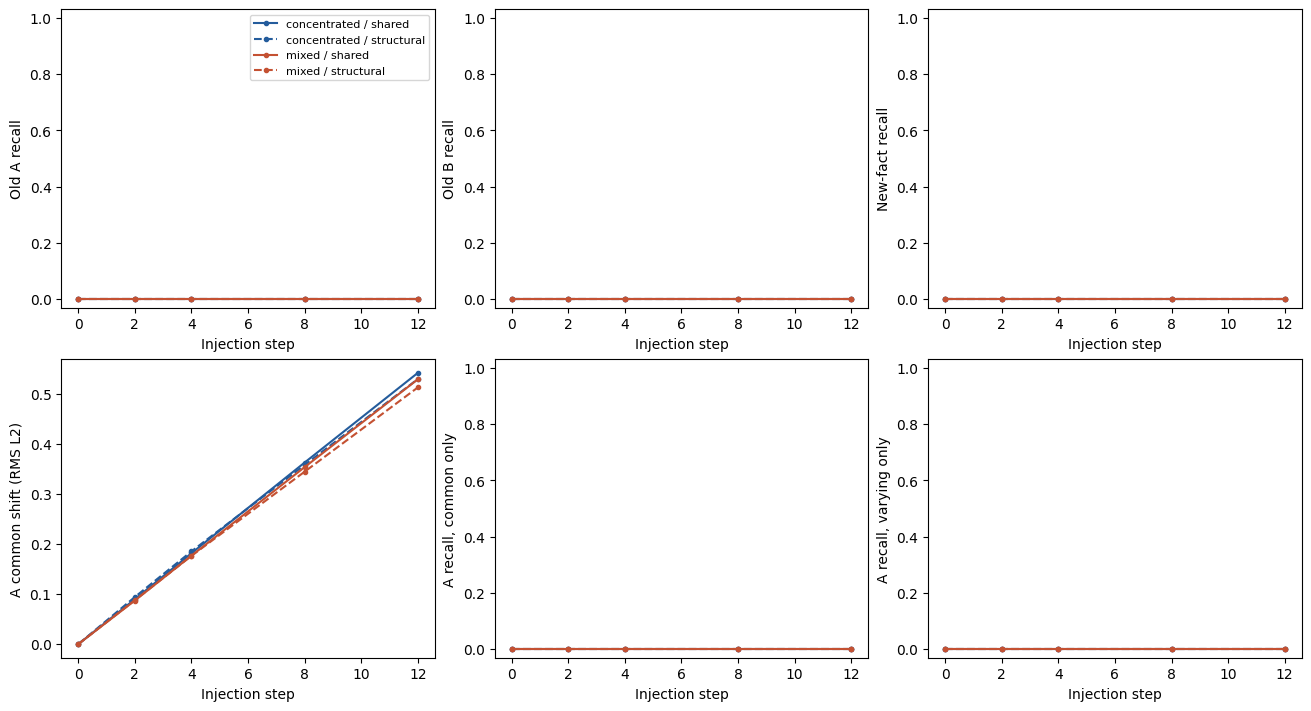

No nonzero shared new-fact recall range across the four arms.


A_start  A_trough  A_end  B_end  new_peak  \
pool         wording                                                 
concentrated shared          0.0       0.0    0.0    0.0       0.0   
             structural      0.0       0.0    0.0    0.0       0.0   
mixed        shared          0.0       0.0    0.0    0.0       0.0   
             structural      0.0       0.0    0.0    0.0       0.0   

                         peak_shift  A_collapse_depth  
pool         wording                                   
concentrated shared        0.542606               0.0  
             structural    0.530219               0.0  
mixed        shared        0.529752               0.0  
             structural    0.513489               0.0

In [ ]:
groups = list(trajectory.groupby(["pool", "wording"], sort=False))
measurements = ["old_A", "old_B", "new", "common_shift", "A_common_only", "A_varying_only"]
low = max(frame["new"].iloc[0] for _, frame in groups)
high = min(frame["new"].max() for _, frame in groups)
matched = []
if high > low:
    for target in np.linspace(low, high, 9):
        for (pool, wording), frame in groups:
            right = np.flatnonzero(frame["new"].to_numpy() >= target)[0]
            hi = frame.iloc[right]
            lo = frame.iloc[max(right - 1, 0)]
            weight = (target - lo["new"]) / (hi["new"] - lo["new"]) if right else 0
            values = {m: lo[m] + weight * (hi[m] - lo[m]) for m in ["step", *measurements]}
            matched.append(dict(pool=pool, wording=wording, target=target, **values))
matched = pd.DataFrame(matched)

labels = {"old_A": "Old A recall", "old_B": "Old B recall", "new": "New-fact recall",
          "common_shift": "A common shift (RMS L2)", "A_common_only": "A recall, common only",
          "A_varying_only": "A recall, varying only"}

def plot_grid(frame, x, x_label, metrics, filename):
    fig, axes = plt.subplots(2, 3, figsize=(13, 7), layout="constrained")
    for ax, metric in zip(axes.flat, metrics):
        for (pool, wording), run in frame.groupby(["pool", "wording"], sort=False):
            ax.plot(run[x], run[metric], marker=".", label=f"{pool} / {wording}",
                    linestyle="-" if wording == "shared" else "--",
                    color="#245c9c" if pool == "concentrated" else "#c45132")
        ax.set(xlabel=x_label, ylabel=labels[metric])
        if metric != "common_shift":
            ax.set_ylim(-0.03, 1.03)
    for ax in list(axes.flat)[len(metrics):]:
        ax.set_visible(False)
    axes.flat[0].legend(fontsize=8)
    fig.savefig(output / filename, dpi=180)
    plt.show()

plot_grid(trajectory, "step", "Injection step", measurements, "by_step.png")
if not matched.empty:
    plot_grid(matched, "target", "Matched new-fact recall",
              [m for m in measurements if m != "new"], "by_matched_recall.png")
    delta = matched.pivot(index=["pool", "target"], columns="wording", values=["old_A", "common_shift"])
    display(delta.xs("structural", level=1, axis=1) - delta.xs("shared", level=1, axis=1))
else:
    print("No nonzero shared new-fact recall range across the four arms.")

summary = (trajectory.groupby(["pool", "wording"], sort=False)
           .agg(A_start=("old_A", "first"), A_trough=("old_A", "min"),
                A_end=("old_A", "last"), B_end=("old_B", "last"),
                new_peak=("new", "max"), peak_shift=("common_shift", "max")))
summary["A_collapse_depth"] = summary["A_start"] - summary["A_trough"]
display(summary)

In [ ]:
import json

for name, table in {"trajectory": trajectory, "matched_recall": matched, "summary": summary.reset_index(),
                    "pool_overlap": pool_overlap, "render_checks": render_checks,
                    "model_overlap": model_overlap, "external_overlap": external_overlap}.items():
    if not table.empty:
        table.to_csv(output / f"{name}.csv", index=False)
manifest = dict(mode=MODE, checkpoint=str(checkpoint) if checkpoint else None,
                checkpoint_sha1=file_hash(checkpoint) if checkpoint else None, corpus_sha1=file_hash(CORPUS),
                partition_sha1=file_hash(cfg.partition_path), injection_seed=INJECTION_SEED,
                injection_lr=cfg.inject.opt.peak_lr, batch_size=cfg.inject.batch_size, steps=STEPS,
                external_encoder=ENCODER_ID if EXTERNAL_EMBEDDINGS else None)
(output / "run.json").write_text(json.dumps(manifest, indent=2))
print(output)

/tmp/biography-wording-gvojyray


## Reading the result

If structural wording lowers external cosine while model overlap, common shift, and old A collapse persist, the external score may miss structure used by the trained model. If the common shift and collapse both shrink at matched new-fact recall, the result supports a role for the rendering policy in forgetting. Compare old B and the common-only and varying-only traces before attributing a change in recall to the common component.

Treat a single checkpoint and injection seed as exploratory. Repeat the paired grid across seeds and checkpoints for an inference about the effect. The absolute answer position and sequence-length diagnostics help interpret any rendering effect.